In [1]:
from pathlib import Path
import pandas as pd, yaml
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
cfg = yaml.safe_load(open(ROOT / "config.yaml", encoding="utf-8"))
INT = ROOT / "data" / "interim"

denue = pd.read_parquet(INT / "denue_zmvm_retail.parquet")
ageb  = pd.read_parquet(INT / "census_ageb_2020.parquet")
imu   = pd.read_parquet(INT / "conapo_imu_ageb_2020.parquet")

def in_zmvm(ent, mun):
    keep = pd.Series(False, index=ent.index)
    for st, muns in cfg["region"]["municipalities"].items():
        s = ent.str.zfill(2) == st
        keep |= s if muns == "all" else s & mun.str.zfill(3).isin(muns)
    return keep

denue = denue[in_zmvm(denue["cve_ent"], denue["cve_mun"])].copy()
ageb  = ageb[in_zmvm(ageb["ENTIDAD"], ageb["MUN"])].copy()
imu   = imu[in_zmvm(imu["ENT"], imu["MUN"])].copy()
print("DENUE rows:", len(denue), "| AGEBs:", len(ageb), "| CONAPO AGEBs:", len(imu))
print(denue.groupby(["store_type", "entidad"]).size().unstack(fill_value=0))

DENUE rows: 247646 | AGEBs: 5751 | CONAPO AGEBs: 5573
entidad                Ciudad de México  Hidalgo  México
store_type                                              
beer_store                         1129       60    1768
chain_store                        2738       61    2304
independent_abarrotes             38900     1507   73593
independent_minisuper               335        5     345
other_food_retail                 53368     1207   69662
supermarket                         313        4     347


In [2]:
def overview(df, name):
    t = pd.DataFrame({"dtype": df.dtypes.astype(str),
                      "missing_%": (df.isna().mean() * 100).round(1),
                      "unique": df.nunique(),
                      "example": df.iloc[0]})
    print(f"=== {name}: {df.shape[0]:,} rows x {df.shape[1]} columns ===")
    return t

overview(denue, "DENUE (ZMVM food retail)")

=== DENUE (ZMVM food retail): 247,646 rows x 24 columns ===


,dtype,missing_%,unique,example
id,str,0.0,247646,7648680
clee,str,0.0,247646,09009461110014701000000000U8
nom_estab,str,0.0,118224,NaN
codigo_act,str,0.0,20,461110
nombre_act,str,0.0,20,"Comercio al por menor en tiendas de abarrotes,..."
per_ocu,str,0.0,7,0 a 5 personas
tipo_asent,str,0.0,43,PUEBLO
nomb_asent,str,0.0,7221,VILLA MILPA ALTA
tipoCenCom,str,84.4,16,NaN
cod_postal,str,0.0,3267,12000


In [3]:
print(denue["nom_estab"].isna().sum(), (denue["nom_estab"].str.strip().isin(["", "NaN", "SIN NOMBRE"])).sum())
print(denue["tipoCenCom"].value_counts().head(8))

57 0
tipoCenCom
MERCADO PUBLICO                      29753
CENTRAL DE ABASTO                     5251
CENTRO Y PLAZA COMERCIAL              2014
PASAJE Y ANDADOR COMERCIAL             551
EDIFICIO COMERCIAL Y DE SERVICIOS      535
OTRO                                   162
TIANGUIS, BAZAR O PULGA                 62
PARQUE RECREATIVO                       55
Name: count, dtype: int64


In [4]:
census_vars = ["POBTOT", "POB0_14", "POB65_MAS", "GRAPROES", "PROM_OCUP",
               "TVIVHAB", "VPH_AUTOM", "VPH_INTER", "VPH_PC"]
print("Missing from file:", [v for v in census_vars if v not in ageb.columns])

ag = ageb[["cvegeo"] + census_vars].copy()
print("\nShare hidden for confidentiality ('*'):")
print((ag[census_vars] == "*").mean().round(3))
for v in census_vars:
    ag[v] = pd.to_numeric(ag[v].replace({"*": None, "N/D": None}), errors="coerce")

display(overview(ag, "Census AGEB (selected variables)"))
display(ag[census_vars].describe().T.round(1))
display(overview(imu, "CONAPO marginalization index"))

Missing from file: []

Share hidden for confidentiality ('*'):
POBTOT       0.000
POB0_14      0.007
POB65_MAS    0.014
GRAPROES     0.004
PROM_OCUP    0.004
TVIVHAB      0.000
VPH_AUTOM    0.010
VPH_INTER    0.008
VPH_PC       0.010
dtype: float64
=== Census AGEB (selected variables): 5,751 rows x 10 columns ===


,dtype,missing_%,unique,example
cvegeo,str,0.0,5751,0900200010010
POBTOT,int64,0.0,4061,3183
POB0_14,float64,0.7,1853,388.0
POB65_MAS,float64,1.4,991,671.0
GRAPROES,float64,0.4,796,11.52
PROM_OCUP,float64,0.4,301,3.67
TVIVHAB,float64,0.0,2214,867.0
VPH_AUTOM,float64,1.0,1292,479.0
VPH_INTER,float64,0.8,1775,692.0
VPH_PC,float64,1.0,1463,532.0


,count,mean,std,min,25%,50%,75%,max
POBTOT,5751.0,3649.6,2589.0,0.0,1835.5,3272.0,4908.0,29065.0
POB0_14,5713.0,760.4,599.1,0.0,331.0,651.0,1038.0,7251.0
POB65_MAS,5671.0,340.6,252.9,0.0,142.0,299.0,491.0,2035.0
GRAPROES,5729.0,10.8,2.0,0.0,9.6,10.5,11.8,17.0
PROM_OCUP,5729.0,3.5,0.6,0.0,3.2,3.6,3.8,6.0
TVIVHAB,5750.0,1047.9,757.9,0.0,536.0,929.0,1403.0,9008.0
VPH_AUTOM,5695.0,469.3,406.9,0.0,219.0,391.0,607.0,6072.0
VPH_INTER,5706.0,728.1,585.9,0.0,343.0,627.0,968.0,7512.0
VPH_PC,5693.0,550.3,488.7,0.0,239.0,450.0,723.0,6919.0


=== CONAPO marginalization index: 5,573 rows x 23 columns ===


,dtype,missing_%,unique,example
CVE_AGEB,str,0.0,5573,0900200010010
ENT,str,0.0,3,09
NOM_ENT,str,0.0,3,Ciudad de México
MUN,str,0.0,58,002
NOM_MUN,str,0.0,63,Azcapotzalco
LOC,str,0.0,105,0001
NOM_LOC,str,0.0,306,Azcapotzalco
AGEB,str,0.0,2589,0010
POB_TOT,int64,0.0,3984,3183
P6A14NAE,float64,0.0,3883,8.627451


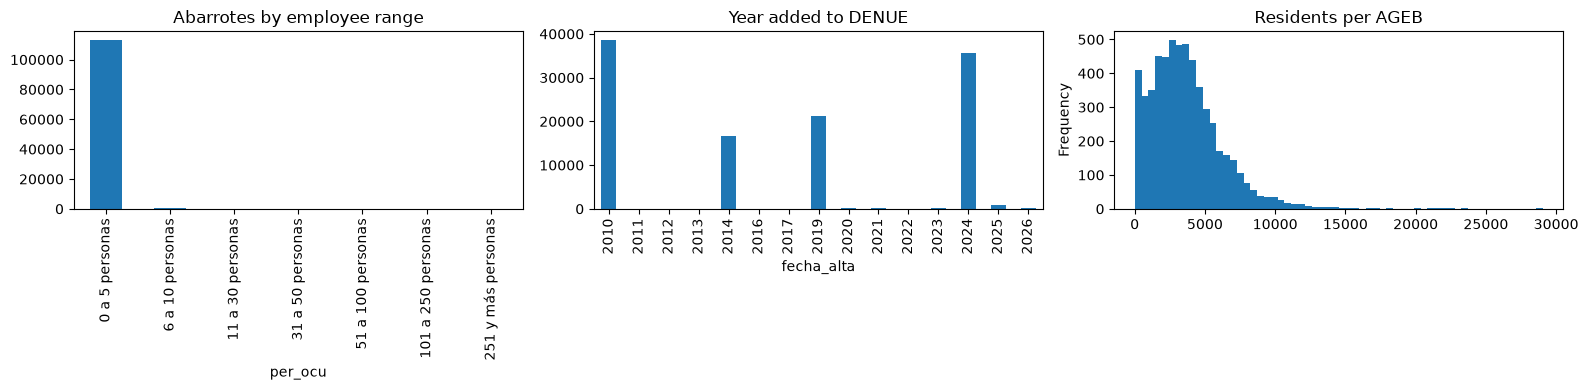

per_ocu
0 a 5 personas        0.994
6 a 10 personas       0.005
11 a 30 personas      0.001
31 a 50 personas      0.000
51 a 100 personas     0.000
101 a 250 personas    0.000
251 y más personas    0.000
Name: proportion, dtype: float64
tipoCenCom
MERCADO PUBLICO                      3375
CENTRAL DE ABASTO                     251
CENTRO Y PLAZA COMERCIAL              228
EDIFICIO COMERCIAL Y DE SERVICIOS     125
Name: count, dtype: int64


In [5]:
import matplotlib.pyplot as plt
ab = denue[denue["store_type"] == "independent_abarrotes"]
size_order = ["0 a 5 personas", "6 a 10 personas", "11 a 30 personas", "31 a 50 personas",
              "51 a 100 personas", "101 a 250 personas", "251 y más personas"]

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ab["per_ocu"].value_counts().reindex(size_order).plot.bar(ax=ax[0], title="Abarrotes by employee range")
ab["fecha_alta"].str[:4].value_counts().sort_index().plot.bar(ax=ax[1], title="Year added to DENUE")
ag["POBTOT"].plot.hist(bins=60, ax=ax[2], title="Residents per AGEB")
plt.tight_layout()
plt.savefig(ROOT / "reports" / "figures" / "s3_distributions.png", dpi=150)
plt.show()
print(ab["per_ocu"].value_counts(normalize=True).reindex(size_order).round(3))
print(ab["tipoCenCom"].value_counts().head(4))

In [6]:
denue["in_central_abasto"] = denue["tipoCenCom"].eq("CENTRAL DE ABASTO")
denue["in_public_market"] = denue["tipoCenCom"].eq("MERCADO PUBLICO")
print(denue.loc[denue["store_type"] == "independent_abarrotes", ["in_central_abasto", "in_public_market"]].sum())

rows = []
for name, df in [("DENUE", denue), ("Census AGEB", ag), ("CONAPO", imu)]:
    for col in df.columns:
        s = df[col]
        num = pd.to_numeric(s, errors="coerce")
        rng = f"{num.min():.2f} – {num.max():.2f}" if num.notna().mean() > 0.9 else f"{s.nunique()} categories"
        rows.append({"source": name, "variable": col, "type": str(s.dtype), "range / values": rng,
                     "missing_%": round(s.isna().mean() * 100, 1), "meaning": "", "unit": ""})
dd = pd.DataFrame(rows)
dd.to_csv(ROOT / "reports" / "data_dictionary.csv", index=False, encoding="utf-8-sig")
print(len(dd), "variables written to reports/data_dictionary.csv")

in_central_abasto     251
in_public_market     3375
dtype: int64
59 variables written to reports/data_dictionary.csv
